In [2]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # less fragmentation for max-batch
import sys, math, time, json, gc, random, threading, platform, itertools
import numpy as np, psutil
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

CFG = dict(
    # model: GPT-2 BPE vocab + tied embeddings -> ~20.0M params
    vocab_size=50257, d_model=256, n_layer=9, n_head=8, ffn_mult=4, seq_len=256,
    # budget
    tokens_per_run_gpu=50_000_000,
    tokens_per_run_cpu=1_000_000,       # CPU is ~100x slower; set force_full_budget=True to insist on 50M
    force_full_budget=False,
    quick_test=False,                   # True -> 2M tokens/run: smoke-test the whole pipeline in minutes
    fixed_batch_gpu=32, fixed_batch_cpu=8,
    # optimisation
    lr=1e-3, max_lr=3e-3, min_lr_frac=0.1, warmup_frac=0.02, weight_decay=0.1, betas=(0.9, 0.95), grad_clip=1.0,
    # reversible variants
    variants=["euler", "midpoint", "verlet", "momentum"],
    momentum_gamma=0.9,
    # max-batch search
    max_batch_cap_gpu=2048, max_batch_cap_cpu=256, max_batch_safety=0.90,
    maxbatch_variants="best",           # "best" or "all"
    run_std_maxbatch=False,             # also train the standard model at ITS max batch (fair comparison)
    # eval / logging
    eval_every_frac=0.10, eval_batches=40, final_eval_batches=200, eval_batch_size=16, log_points=25,
    ce_chunk_tokens=2048,               # chunked+checkpointed LM-head/CE (same for all runs) so logits don't dominate memory
    seed=1337,
    use_drive=False, resume=True, save_checkpoints=False,
    out_dir="/content/rev_llm" if os.path.isdir("/content") else "./rev_llm",
)

def banner(title):
    print("\n" + "=" * 110 + f"\n{title}\n" + "=" * 110, flush=True)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

banner("STAGE 0 - ENVIRONMENT")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    _p = torch.cuda.get_device_properties(0)
    HW_NAME, HW_MEM_GB = _p.name, _p.total_memory / 1e9
    AMP_DTYPE = torch.bfloat16 if _p.major >= 8 else torch.float16
    USE_AMP = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
else:
    HW_NAME, HW_MEM_GB = (platform.processor() or platform.machine() or "CPU"), psutil.virtual_memory().total / 1e9
    AMP_DTYPE, USE_AMP = torch.bfloat16, False
    torch.set_num_threads(os.cpu_count() or 1)

if CFG["quick_test"]:
    TOKENS_PER_RUN = 2_000_000
elif DEVICE == "cuda" or CFG["force_full_budget"]:
    TOKENS_PER_RUN = CFG["tokens_per_run_gpu"]
else:
    TOKENS_PER_RUN = CFG["tokens_per_run_cpu"]
FIXED_BATCH = CFG["fixed_batch_gpu"] if DEVICE == "cuda" else CFG["fixed_batch_cpu"]
MAX_BATCH_CAP = CFG["max_batch_cap_gpu"] if DEVICE == "cuda" else CFG["max_batch_cap_cpu"]
V, T = CFG["vocab_size"], CFG["seq_len"]

def peak_flops(name):  # approximate dense tensor-core peak for the AMP dtype
    for k, v in [("H100", 989e12), ("A100", 312e12), ("L4", 121e12), ("A10", 125e12),
                 ("V100", 125e12), ("T4", 65e12), ("P100", 18.7e12), ("K80", 8.7e12)]:
        if k in name: return v
    return None
PEAK_FLOPS = peak_flops(HW_NAME) if DEVICE == "cuda" else None

if CFG["use_drive"] and os.path.isdir("/content"):
    from google.colab import drive
    drive.mount("/content/drive"); CFG["out_dir"] = "/content/drive/MyDrive/rev_llm"
OUT = CFG["out_dir"]; os.makedirs(OUT, exist_ok=True)

def amp_ctx(enabled=True):
    return torch.autocast(device_type=DEVICE, dtype=AMP_DTYPE, enabled=USE_AMP and enabled)

def make_scaler():
    en = USE_AMP and AMP_DTYPE == torch.float16
    try: return torch.amp.GradScaler("cuda", enabled=en)
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=en)

def sync():
    if DEVICE == "cuda": torch.cuda.synchronize()

def free_mem():
    gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

def is_oom(e):
    s = str(e).lower()
    return isinstance(e, getattr(torch.cuda, "OutOfMemoryError", ())) or "out of memory" in s or "cublas_status_alloc_failed" in s

class PeakRSS:
    """Background sampler of process RSS (used for CPU memory peaks; host RAM on GPU)."""
    def __init__(self, interval=0.02): self.p, self.interval = psutil.Process(), interval
    def start(self):
        self.base = self.peak = self.p.memory_info().rss; self._stop = False
        self.t = threading.Thread(target=self._run, daemon=True); self.t.start(); return self
    def _run(self):
        while not self._stop:
            self.peak = max(self.peak, self.p.memory_info().rss); time.sleep(self.interval)
    def stop(self):
        self._stop = True; self.t.join(); self.peak = max(self.peak, self.p.memory_info().rss); return self

info = {
    "python": sys.version.split()[0], "torch": torch.__version__, "device": DEVICE, "hardware": HW_NAME,
    "device memory (GB)": f"{HW_MEM_GB:.1f}", "host RAM (GB)": f"{psutil.virtual_memory().total/1e9:.1f}",
    "cpu cores": os.cpu_count(), "precision": f"{str(AMP_DTYPE).replace('torch.', '')} + autocast" + (" + GradScaler" if AMP_DTYPE == torch.float16 else "" if USE_AMP else ""),
    "peak FLOPS (approx)": f"{PEAK_FLOPS/1e12:.0f} TFLOPS" if PEAK_FLOPS else "n/a",
    "tokens per run": f"{TOKENS_PER_RUN:,}", "fixed batch (seqs)": FIXED_BATCH, "seq len": T, "output dir": OUT,
}
for k, v in info.items(): print(f" {k:<22}: {v}")
if DEVICE == "cpu" and not CFG["force_full_budget"]:
    print(" NOTE: No GPU -> token budget reduced to keep runtime sane. Set CFG['force_full_budget']=True for 50M.")

RESULTS_PATH = f"{OUT}/results.json"
FINGERPRINT = f"{DEVICE}|{HW_NAME}|{TOKENS_PER_RUN}|{CFG['d_model']}x{CFG['n_layer']}|T{T}|B{FIXED_BATCH}"
RESULTS = {"meta": {}, "diag": {}, "probe": {}, "runs": {}}
if CFG["resume"] and os.path.exists(RESULTS_PATH):
    _old = json.load(open(RESULTS_PATH))
    if _old.get("meta", {}).get("fingerprint") == FINGERPRINT:
        RESULTS = _old; print(f" resumed: {len(RESULTS['runs'])} finished runs found -> {list(RESULTS['runs'])}")
    else:
        print(" results.json exists but config/hardware changed -> starting fresh")
RESULTS["meta"].update(info); RESULTS["meta"]["fingerprint"] = FINGERPRINT
RESULTS["meta"]["cfg"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}

def save_results():
    tmp = RESULTS_PATH + ".tmp"
    with open(tmp, "w") as f: json.dump(RESULTS, f, indent=1, default=float)
    os.replace(tmp, RESULTS_PATH)

save_results()




STAGE 0 - ENVIRONMENT
 python                : 3.13.16
 torch                 : 2.11.0+cu130
 device                : cuda
 hardware              : Tesla T4
 device memory (GB)    : 15.6
 host RAM (GB)         : 13.6
 cpu cores             : 2
 precision             : float16 + autocast + GradScaler
 peak FLOPS (approx)   : 65 TFLOPS
 tokens per run        : 50,000,000
 fixed batch (seqs)    : 32
 seq len               : 256
 output dir            : /content/rev_llm
 resumed: 0 finished runs found -> []


In [3]:
banner("STAGE 1 - DATA (WikiText-103, GPT-2 BPE via tiktoken)")
import tiktoken
ENC = tiktoken.get_encoding("gpt2")
TRAIN_PATH, VAL_PATH, META_PATH = f"{OUT}/train_u16.npy", f"{OUT}/val_u16.npy", f"{OUT}/data_meta.json"

def tokenize(texts, label, bs=20000):
    parts, t0, n = [], time.time(), len(texts)
    for i in range(0, n, bs):
        ids = ENC.encode_ordinary_batch(texts[i:i + bs], num_threads=os.cpu_count() or 2)
        parts.append(np.fromiter(itertools.chain.from_iterable(ids), dtype=np.uint16))
        if (i // bs) % 20 == 0 or i + bs >= n:
            print(f" [{label}] {min(i+bs, n):>9,}/{n:,} docs | {sum(len(p) for p in parts)/1e6:8.2f}M tokens | {time.time()-t0:5.0f}s", flush=True)
    return np.concatenate(parts)

if all(os.path.exists(p) for p in (TRAIN_PATH, VAL_PATH, META_PATH)):
    TRAIN, VAL = np.load(TRAIN_PATH), np.load(VAL_PATH); DATA_META = json.load(open(META_PATH))
    print(" loaded cached token files")
else:
    try:
        from datasets import load_dataset
        try: ds = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
        except Exception: ds = load_dataset("wikitext", "wikitext-103-raw-v1")
        tr_txt = [t for t in ds["train"]["text"] if t.strip()]
        va_txt = [t for t in ds["validation"]["text"] if t.strip()]
        dname = "WikiText-103 (raw)"
    except Exception as e:
        print(f" WikiText-103 unavailable ({type(e).__name__}: {e}) -> fallback TinyShakespeare (many epochs!)")
        import urllib.request
        txt = urllib.request.urlopen("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt").read().decode()
        cut = int(0.95 * len(txt)); tr_txt, va_txt = [txt[:cut]], [txt[cut:]]
        dname = "TinyShakespeare (fallback)"
    TRAIN, VAL = tokenize(tr_txt, "train"), tokenize(va_txt, "val")
    DATA_META = {"name": dname}
    np.save(TRAIN_PATH, TRAIN); np.save(VAL_PATH, VAL); json.dump(DATA_META, open(META_PATH, "w"))
    del tr_txt, va_txt; gc.collect()

EB = CFG["eval_batch_size"]
VAL_STARTS = np.arange((len(VAL) - 1) // T) * T
N_VAL_BATCHES = max(1, len(VAL_STARTS) // EB)

RESULTS["meta"].update(dataset=DATA_META["name"], train_tokens=int(len(TRAIN)), val_tokens=int(len(VAL)))
print(f" dataset               : {DATA_META['name']}")
print(f" train tokens          : {len(TRAIN):,}")
print(f" val tokens            : {len(VAL):,}")
print(f" tokens per run        : {TOKENS_PER_RUN:,} -> {TOKENS_PER_RUN/len(TRAIN):.2f} epochs of train split")
print(f" sample                : {ENC.decode(TRAIN[:60].tolist())!r}")

def to_xy(data, starts, T=T):
    idx = starts[:, None] + np.arange(T + 1)[None, :]
    chunk = torch.from_numpy(data[idx].astype(np.int64))
    x, y = chunk[:, :-1].contiguous(), chunk[:, 1:].contiguous()
    if DEVICE == "cuda":
        x, y = x.pin_memory().to(DEVICE, non_blocking=True), y.pin_memory().to(DEVICE, non_blocking=True)
    return x, y

class TrainStream:
    """Deterministic window order -> every run sees the same tokens in the same order, whatever the batch size."""
    def __init__(self, data, T, seed):
        self.data, self.T, self.seed, self.epoch = data, T, seed, 0
        self.nwin = (len(data) - 1) // T; self._shuffle()
    def _shuffle(self):
        self.order = np.random.default_rng(self.seed + self.epoch).permutation(self.nwin) * self.T; self.ptr = 0
    def next(self, B):
        if self.ptr + B > self.nwin: self.epoch += 1; self._shuffle()
        s = self.order[self.ptr:self.ptr + B]; self.ptr += B
        return to_xy(self.data, s, self.T)

@torch.no_grad()
def evaluate(model, max_batches):
    model.eval(); losses = []
    with amp_ctx():
        for i in range(min(max_batches, N_VAL_BATCHES)):
            x, y = to_xy(VAL, VAL_STARTS[i * EB:(i + 1) * EB])
            losses.append(model(x, y).float())
    model.train()
    return torch.stack(losses).mean().item()



STAGE 1 - DATA (WikiText-103, GPT-2 BPE via tiktoken)


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/1801350 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

 [train]    20,000/1,165,029 docs |     2.00M tokens |     2s
 [train]   420,000/1,165,029 docs |    42.31M tokens |    38s
 [train]   820,000/1,165,029 docs |    82.96M tokens |    77s
 [train] 1,165,029/1,165,029 docs |   117.92M tokens |   110s
 [val]     2,461/2,461 docs |     0.25M tokens |     0s
 dataset               : WikiText-103 (raw)
 train tokens          : 117,920,140
 val tokens            : 247,289
 tokens per run        : 50,000,000 -> 0.42 epochs of train split
 sample                : ' = Valkyria Chronicles III = \n Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside'


## model (standard and four reversible integrators)

In [4]:
INTEGRATOR_DOC = {
    "std":      "x' = x + f(x)",                                                    # [forward-Euler residual; NOT invertible -> stores activations]
    "euler":    "a' = a + F(b);  b' = b + G(a')",                                    # [symplectic Euler = RevNet additive coupling, 1st order]
    "midpoint": "x_{k+1} = x_{k-1} + f(x_k)",                                         # [explicit midpoint / leapfrog two-step, 2h folded into f]
    "verlet":   "a' = a + ½F(b); b' = b + G(a'); a' = a + ½F(b')",                    # [Störmer-Verlet, 2nd order, symmetric; 2 attn calls/layer]
    "momentum": "v' = γv + (1-γ)f(x); x' = x + v'",                                   # [MomentumNet / heavy-ball; inverse divides by γ]
} # F = attn(LN), G = MLP(LN), f = full pre-LN block (attn then MLP)

class CausalSelfAttention(nn.Module):
    def __init__(self, d, n_head):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
    def forward(self, x):
        B, Tq, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = (t.view(B, Tq, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).contiguous().view(B, Tq, C))

class MLP(nn.Module):
    def __init__(self, d, mult):
        super().__init__()
        self.fc = nn.Linear(d, mult * d, bias=False)
        self.proj = nn.Linear(mult * d, d, bias=False)
    def forward(self, x): return self.proj(F.gelu(self.fc(x), approximate="tanh"))

class Sublayers(nn.Module):
    """Identical parameters for every variant: LN1+attn, LN2+MLP."""
    def __init__(self):
        super().__init__()
        d = CFG["d_model"]
        self.ln1, self.attn = nn.LayerNorm(d), CausalSelfAttention(d, CFG["n_head"])
        self.ln2, self.mlp = nn.LayerNorm(d), MLP(d, CFG["ffn_mult"])
    def f_attn(self, x): return self.attn(self.ln1(x))
    def g_mlp(self, x):  return self.mlp(self.ln2(x))
    def full(self, x):
        h = self.f_attn(x); return h + self.g_mlp(x + h)

class StdBlock(Sublayers):
    def forward(self, x): return x + self.full(x)


class EulerBlock(Sublayers):
    def fwd(self, a, b):
        a = a + self.f_attn(b); b = b + self.g_mlp(a); return a, b
    def inv(self, a, b):
        b = b - self.g_mlp(a); a = a - self.f_attn(b); return a, b

class MidpointBlock(Sublayers):
    def fwd(self, prev, cur): return cur, prev + self.full(cur)
    def inv(self, cur, nxt):  return nxt - self.full(cur), cur

class VerletBlock(Sublayers):
    def fwd(self, a, b):
        a = a + 0.5 * self.f_attn(b); b = b + self.g_mlp(a); a = a + 0.5 * self.f_attn(b); return a, b
    def inv(self, a, b):
        a = a - 0.5 * self.f_attn(b); b = b - self.g_mlp(a); a = a - 0.5 * self.f_attn(b); return a, b

class MomentumBlock(Sublayers):
    def fwd(self, x, v):
        g = CFG["momentum_gamma"]; v = g * v + (1 - g) * self.full(x); return x + v, v
    def inv(self, x, v):
        g = CFG["momentum_gamma"]; x = x - v; v = (v - (1 - g) * self.full(x)) / g; return x, v

BLOCKS = {"std": StdBlock, "euler": EulerBlock, "midpoint": MidpointBlock, "verlet": VerletBlock, "momentum": MomentumBlock}

def autocast_state():
    try:
        return dict(device_type=DEVICE, dtype=torch.get_autocast_dtype(DEVICE), enabled=torch.is_autocast_enabled(DEVICE))
    except (TypeError, AttributeError):
        if DEVICE == "cuda":
            return dict(device_type="cuda", dtype=torch.get_autocast_gpu_dtype(), enabled=torch.is_autocast_enabled())
        return dict(device_type="cpu", dtype=torch.get_autocast_cpu_dtype(), enabled=torch.is_autocast_cpu_enabled())

class RevStackFn(torch.autograd.Function):
    """Runs all reversible blocks without storing activations; backward reconstructs each layer's
    input by exact inversion, re-runs that layer with grad, and back-propagates (memory O(1) in depth)."""
    @staticmethod
    def forward(ctx, a, b, blocks, ac_kw):
        ctx.blocks, ctx.ac_kw = blocks, ac_kw
        with torch.no_grad():
            for blk in blocks: a, b = blk.fwd(a, b)
        ctx.save_for_backward(a, b)
        return a, b

    @staticmethod
    def backward(ctx, ga, gb):
        a, b = (t.detach() for t in ctx.saved_tensors)
        ga = torch.zeros_like(a) if ga is None else ga
        gb = torch.zeros_like(b) if gb is None else gb
        for blk in reversed(ctx.blocks):
            with torch.no_grad(), torch.autocast(**ctx.ac_kw):
                a, b = blk.inv(a, b)
            a, b = a.detach().requires_grad_(True), b.detach().requires_grad_(True)
            with torch.enable_grad(), torch.autocast(**ctx.ac_kw):
                oa, ob = blk.fwd(a, b)
            torch.autograd.backward((oa, ob), (ga, gb))  # accumulates parameter grads
            ga = a.grad if a.grad is not None else torch.zeros_like(a)
            gb = b.grad if b.grad is not None else torch.zeros_like(b)
            a, b = a.detach(), b.detach()
        return (ga if ctx.needs_input_grad[0] else None, gb if ctx.needs_input_grad[1] else None, None, None)

def _ce_chunk(h, w, t):
    return F.cross_entropy(F.linear(h, w).float(), t, reduction="sum")

def chunked_ce(h, w, t, chunk):
    N, total = h.shape[0], 0.0
    for i in range(0, N, chunk):
        hs, ts = h[i:i + chunk], t[i:i + chunk]
        total = total + (checkpoint(_ce_chunk, hs, w, ts, use_reentrant=False) if torch.is_grad_enabled() else _ce_chunk(hs, w, ts))
    return total / N

class GPT(nn.Module):
    READOUT = {"euler": "mean", "verlet": "mean", "midpoint": "second", "momentum": "first"}
    def __init__(self, arch):
        super().__init__()
        self.arch = arch
        d, L = CFG["d_model"], CFG["n_layer"]
        self.wte = nn.Embedding(CFG["vocab_size"], d)
        self.wpe = nn.Embedding(CFG["seq_len"], d)
        self.blocks = nn.ModuleList([BLOCKS[arch]() for _ in range(L)])
        self.ln_f = nn.LayerNorm(d)
        self.rev_backward = arch != "std"
        for n, p in self.named_parameters():
            if p.dim() >= 2:
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * L) if n.endswith("proj.weight") else 0.02)
    def num_params(self): return sum(p.numel() for p in self.parameters())  # tied head counted once
    def embed(self, idx):
        return self.wte(idx) + self.wpe(torch.arange(idx.shape[1], device=idx.device))
    def init_state(self, e):
        return (e, torch.zeros_like(e)) if self.arch == "momentum" else (e, e)
    def readout(self, a, b):
        r = self.READOUT[self.arch]
        return 0.5 * (a + b) if r == "mean" else (b if r == "second" else a)
    def hidden(self, idx):
        e = self.embed(idx)
        if self.arch == "std":
            x = e
            for blk in self.blocks: x = blk(x)
        else:
            a, b = self.init_state(e)
            if self.rev_backward and torch.is_grad_enabled():
                a, b = RevStackFn.apply(a, b, list(self.blocks), autocast_state())
            else:
                for blk in self.blocks: a, b = blk.fwd(a, b)
            x = self.readout(a, b)
        return self.ln_f(x)
    def forward(self, idx, targets=None):
        h = self.hidden(idx)
        if targets is None: return F.linear(h[:, -1, :], self.wte.weight)
        return chunked_ce(h.reshape(-1, h.shape[-1]), self.wte.weight, targets.reshape(-1), CFG["ce_chunk_tokens"])

def make_optimizer(model, lr):
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    groups = [dict(params=decay, weight_decay=CFG["weight_decay"]), dict(params=no_decay, weight_decay=0.0)]
    kw = dict(lr=lr, betas=CFG["betas"], eps=1e-8)
    if DEVICE == "cuda":
        try: return torch.optim.AdamW(groups, fused=True, **kw)
        except Exception: pass
    return torch.optim.AdamW(groups, **kw)

_m = GPT("std")
N_PARAMS = _m.num_params()
FLOPS_PER_TOKEN = 6 * (N_PARAMS - _m.wpe.weight.numel()) + 12 * CFG["n_layer"] * T * CFG["d_model"]
del _m
PROMPTS = ["The history of the city", "In 1998, the band released"]

@torch.no_grad()
def generate(model, prompt, n_new=60, temperature=0.8, top_k=40, seed=0):
    g = torch.Generator(device=DEVICE).manual_seed(seed)
    model.eval()
    idx = torch.tensor([ENC.encode(prompt)], dtype=torch.long, device=DEVICE)
    for _ in range(n_new):
        with amp_ctx(): logits = model(idx[:, -T:]).float() / temperature
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = -float("inf")
        idx = torch.cat([idx, torch.multinomial(torch.softmax(logits, -1), 1, generator=g)], 1)
    model.train()
    return ENC.decode(idx[0].tolist())




model sanity check and reversibility diagnostics

In [5]:
banner("STAGE 2 - MODEL / PARAMETERS / INIT SANITY")
XV, YV = to_xy(VAL, VAL_STARTS[:8])
ARCH_INFO = {}
for arch in ["std"] + CFG["variants"]:
    seed_all(CFG["seed"]); m = GPT(arch).to(DEVICE)
    with torch.no_grad(), amp_ctx(): l0 = m(XV, YV).item()
    ARCH_INFO[arch] = dict(params=m.num_params(), init_loss=l0)
    print(f" {arch:9s} params {m.num_params()/1e6:6.2f}M | init loss {l0:.3f} (ln V = {math.log(V):.3f}) | {INTEGRATOR_DOC[arch]}")
    del m
print(f" embedding params {V*CFG['d_model']/1e6:.2f}M (tied with LM head), non-embedding {(N_PARAMS - V*CFG['d_model'])/1e6:.2f}M")
print(f" model FLOPS/token (6N + attn) = {FLOPS_PER_TOKEN/1e6:.1f} MFLOPS -> {TOKENS_PER_RUN*FLOPS_PER_TOKEN/1e15:.2f} PFLOPS per run")
RESULTS["meta"].update(n_params=N_PARAMS, flops_per_token=FLOPS_PER_TOKEN, arch_info=ARCH_INFO)

@torch.no_grad()
def inversion_error(model, x, use_amp):
    """Forward through all layers storing states, then invert from the top; compare reconstructions."""
    with amp_ctx(use_amp):
        a, b = model.init_state(model.embed(x)); stack = [(a, b)]
        for blk in model.blocks: a, b = blk.fwd(a, b); stack.append((a, b))
        per_layer = []
        for i in reversed(range(len(model.blocks))):
            a, b = model.blocks[i].inv(a, b); a0, b0 = stack[i]
            per_layer.append(max((a - a0).abs().max().item(), (b - b0).abs().max().item()))
        a0, b0 = stack[0]
        rel = ((a - a0).norm() + (b - b0).norm()) / (a0.norm() + b0.norm() + 1e-12)
    return dict(max_abs=per_layer[-1], rel=rel.item(), per_layer=per_layer[::-1])

def grad_fidelity(model, x, y, use_amp):
    """Gradients from reversible backward vs. ordinary autograd (stored activations) on the same batch."""
    g = {}
    for mode in (False, True):
        model.rev_backward = mode; model.zero_grad(set_to_none=True)
        with amp_ctx(use_amp): loss = model(x, y)
        (loss * 1024.0).backward()                # static scale avoids fp16 underflow
        g[mode] = torch.cat([p.grad.float().flatten() for p in model.parameters()]) / 1024.0
    model.rev_backward = True; model.zero_grad(set_to_none=True)
    d = g[False] - g[True]
    return dict(cos=F.cosine_similarity(g[False], g[True], dim=0).item(),
                rel_err=(d.norm() / g[False].norm()).item(), max_abs=d.abs().max().item())



STAGE 2 - MODEL / PARAMETERS / INIT SANITY
 std       params  20.02M | init loss 10.861 (ln V = 10.825) | x' = x + f(x)
 euler     params  20.02M | init loss 10.861 (ln V = 10.825) | a' = a + F(b);  b' = b + G(a')
 midpoint  params  20.02M | init loss 10.905 (ln V = 10.825) | x_{k+1} = x_{k-1} + f(x_k)
 verlet    params  20.02M | init loss 10.869 (ln V = 10.825) | a' = a + ½F(b); b' = b + G(a'); a' = a + ½F(b')
 momentum  params  20.02M | init loss 10.867 (ln V = 10.825) | v' = γv + (1-γ)f(x); x' = x + v'
 embedding params 12.87M (tied with LM head), non-embedding 7.15M
 model FLOPS/token (6N + attn) = 126.8 MFLOPS -> 6.34 PFLOPS per run


In [6]:
banner("STAGE 3 - REVERSIBILITY DIAGNOSTICS AT INIT (inversion exactness + gradient fidelity)")
print(f" {'variant':9s} | {'inv rel err fp32':>16s} | {'inv rel err amp':>15s} | {'grad cos fp32':>13s} | {'grad relerr fp32':>16s} | {'grad cos amp':>12s} | {'grad relerr amp':>15s}")
for v in CFG["variants"]:
    seed_all(CFG["seed"]); m = GPT(v).to(DEVICE)
    d = dict(inv_fp32=inversion_error(m, XV, False), inv_amp=inversion_error(m, XV, True),
             grad_fp32=grad_fidelity(m, XV, YV, False), grad_amp=grad_fidelity(m, XV, YV, True))
    RESULTS["diag"][v] = d
    print(f" {v:9s} | {d['inv_fp32']['rel']:16.2e} | {d['inv_amp']['rel']:15.2e} | {d['grad_fp32']['cos']:13.8f} | "
          f" {d['grad_fp32']['rel_err']:16.2e} | {d['grad_amp']['cos']:12.8f} | {d['grad_amp']['rel_err']:15.2e}")
    del m; free_mem()
save_results()
print(" (rel err ~1e-7 fp32 = exact to round-off; cos~1 means reversible backward gives the true gradient)")


STAGE 3 - REVERSIBILITY DIAGNOSTICS AT INIT (inversion exactness + gradient fidelity)
 variant   | inv rel err fp32 | inv rel err amp | grad cos fp32 | grad relerr fp32 | grad cos amp | grad relerr amp
 euler     |         9.37e-07 |        7.33e-04 |    1.00000000 |          4.46e-07 |   0.99999988 |        3.10e-04
 midpoint  |         1.49e-06 |        1.52e-03 |    1.00000000 |          5.57e-07 |   1.00000000 |        4.91e-04
 verlet    |         8.32e-07 |        6.74e-04 |    0.99999988 |          3.51e-07 |   1.00000000 |        3.05e-04
 momentum  |         1.06e-06 |        9.98e-04 |    1.00000000 |          4.31e-07 |   0.99999994 |        4.55e-04
 (rel err ~1e-7 fp32 = exact to round-off; cos~1 means reversible backward gives the true gradient)


memory profiling and maximum batch search

In [7]:
banner("STAGE 4 - MEMORY PROFILING & MAX BATCH SEARCH (train step = fwd+bwd+AdamW)")

def build_train_objs(arch):
    seed_all(CFG["seed"]); m = GPT(arch).to(DEVICE)
    return m, make_optimizer(m, CFG["lr"]), make_scaler()

def probe_step(m, opt, scaler, B):
    x = torch.randint(0, V, (B, T), device=DEVICE); y = torch.randint(0, V, (B, T), device=DEVICE)
    with amp_ctx(): loss = m(x, y)
    scaler.scale(loss).backward()
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)

def _slope(curve):
    if len(curve) < 2: return None
    return float(np.polyfit([c["B"] for c in curve], [c["peak_gb"] for c in curve], 1)[0] * 1e3)  # MB per sequence

def find_max_batch_gpu(arch, cap):
    m, opt, sc = build_train_objs(arch)
    probe_step(m, opt, sc, 1); sync(); static = torch.cuda.memory_allocated()
    curve = []
    def attempt(B):
        free_mem(); torch.cuda.reset_peak_memory_stats()
        ok, dt = True, None
        try:
            probe_step(m, opt, sc, B); sync()
            t0 = time.perf_counter(); probe_step(m, opt, sc, B); sync(); dt = time.perf_counter() - t0
        except RuntimeError as e:
            if not is_oom(e): raise
            ok = False
        opt.zero_grad(set_to_none=True)
        peak = torch.cuda.max_memory_allocated() / 1e9
        free_mem()
        print(f" [{arch:9s}] B={B:5d} " + (f"OK  peak {peak:6.2f} GB  ~{B*T/dt:>9,.0f} tok/s" if ok else "OOM"), flush=True)
        if ok: curve.append(dict(B=B, peak_gb=peak, tok_s=B * T / dt))
        return ok
    lo, hi, B = 0, None, 8
    while B <= cap:
        if attempt(B): lo, B = B, B * 2
        else: hi = B; break
    if lo == 0:
        B = 4
        while B >= 1 and not attempt(B): B //= 2
        lo = max(B, 1)
    if hi is not None:
        while hi - lo > max(1, lo // 16):
            mid = (lo + hi) // 2
            if attempt(mid): lo = mid
            else: hi = mid
    del m, opt, sc; free_mem()
    curve.sort(key=lambda c: c["B"])
    return dict(max_batch=lo, capped=hi is None, estimated=False, static_gb=static / 1e9, curve=curve, act_mb_per_seq=_slope(curve))

def find_max_batch_cpu(arch, cap):
    m, opt, sc = build_train_objs(arch)
    probe_step(m, opt, sc, 1); gc.collect(); static = psutil.Process().memory_info().rss
    curve = []
    for B in (2, 4, 8):
        pr = PeakRSS().start(); t0 = time.perf_counter(); probe_step(m, opt, sc, B); dt = time.perf_counter() - t0; pr.stop()
        curve.append(dict(B=B, peak_gb=pr.peak / 1e9, tok_s=B * T / dt))
        print(f" [{arch:9s}] B={B:5d} peak RSS {pr.peak/1e9:6.2f} GB  ~{B*T/dt:>8,.0f} tok/s", flush=True)
    slope_gb = max((_slope(curve) or 0) / 1e3, 1e-4)
    maxb = int(max(1, min(cap, 0.5 * psutil.virtual_memory().available / 1e9 / slope_gb)))
    del m, opt, sc; free_mem()
    return dict(max_batch=maxb, capped=maxb >= cap, estimated=True, static_gb=static / 1e9, curve=curve, act_mb_per_seq=slope_gb * 1e3)

for arch in ["std"] + CFG["variants"]:
    if arch in RESULTS["probe"]:
        print(f" [{arch}] probe cached -> max batch {RESULTS['probe'][arch]['max_batch']}"); continue
    print(f" probing {arch} ...")
    r = find_max_batch_gpu(arch, MAX_BATCH_CAP) if DEVICE == "cuda" else find_max_batch_cpu(arch, MAX_BATCH_CAP)
    RESULTS["probe"][arch] = r; save_results()

print(f"\n {'arch':9s} | {'max batch':>10s} | {'static GB':>9s} | {'act MB/seq':>10s} | {'x vs std':>8s} | note")
std_max = RESULTS["probe"]["std"]["max_batch"]
for arch, r in RESULTS["probe"].items():
    note = ("hit cap " if r["capped"] else "") + ("(RAM estimate)" if r["estimated"] else "")
    s = r["act_mb_per_seq"]
    print(f" {arch:9s} | {r['max_batch']:10d} | {r['static_gb']:9.3f} | {(f'{s:10.2f}' if s else 'n/a'):>10s} | {r['max_batch']/std_max:7.2f}x | {note}")

if FIXED_BATCH > std_max * CFG["max_batch_safety"]:
    nb = 2 ** int(math.log2(max(1, std_max * CFG["max_batch_safety"])))
    print(f" WARNING: Fixed batch {FIXED_BATCH} does not fit the standard model -> using {nb}")
    FIXED_BATCH = nb
print(f"\n FIXED BATCH used for baseline + all reversible variants: {FIXED_BATCH} x {T} = {FIXED_BATCH*T:,} tokens/step")
RESULTS["meta"]["fixed_batch_used"] = FIXED_BATCH; save_results()




STAGE 4 - MEMORY PROFILING & MAX BATCH SEARCH (train step = fwd+bwd+AdamW)
 probing std ...
 [std      ] B=    8 OK  peak   1.71 GB  ~   22,837 tok/s
 [std      ] B=   16 OK  peak   1.91 GB  ~   31,696 tok/s
 [std      ] B=   32 OK  peak   2.27 GB  ~   33,621 tok/s
 [std      ] B=   64 OK  peak   2.98 GB  ~   33,669 tok/s
 [std      ] B=  128 OK  peak   4.39 GB  ~   33,447 tok/s
 [std      ] B=  256 OK  peak   7.23 GB  ~   33,022 tok/s
 [std      ] B=  512 OK  peak  12.89 GB  ~   31,988 tok/s
 [std      ] B= 1024 OOM
 [std      ] B=  768 OOM
 [std      ] B=  640 OOM
 [std      ] B=  576 OK  peak  14.31 GB  ~   30,844 tok/s
 [std      ] B=  608 OK  peak  15.02 GB  ~   30,900 tok/s
 probing euler ...
 [euler    ] B=    8 OK  peak   1.53 GB  ~   25,649 tok/s
 [euler    ] B=   16 OK  peak   1.57 GB  ~   27,779 tok/s
 [euler    ] B=   32 OK  peak   1.59 GB  ~   28,274 tok/s
 [euler    ] B=   64 OK  peak   1.63 GB  ~   28,517 tok/s
 [euler    ] B=  128 OK  peak   1.71 GB  ~   28,633 tok/s
 

training loop

In [9]:
def lr_at(step, steps, warmup, peak):
    if step < warmup: return peak * (step + 1) / warmup
    p = min(1.0, (step - warmup) / max(1, steps - warmup))
    return peak * (CFG["min_lr_frac"] + (1 - CFG["min_lr_frac"],) * 0.5 * (1 + math.cos(math.pi * p))) if isinstance(CFG["min_lr_frac"], tuple) else peak * (CFG["min_lr_frac"] + (1 - CFG["min_lr_frac"]) * 0.5 * (1 + math.cos(math.pi * p)))

def train_run(name, arch, B, tokens, lr):
    runs = RESULTS["runs"]
    if CFG["resume"] and name in runs:
        print(f" [{name}] already finished (results.json) -> skipped"); return runs[name]
    tps = B * T
    steps = max(1, math.ceil(tokens / tps))
    warmup = min(max(5, int(CFG["warmup_frac"] * steps)), max(1, steps // 10))
    eval_every = max(1, round(steps * CFG["eval_every_frac"]))
    log_every = max(1, steps // CFG["log_points"])
    banner(f"RUN {name} | arch={arch} | batch={B}x{T}={tps:,} tok/step | steps={steps:,} | "
           f"tokens={steps*tps/1e6:.2f}M | peak lr={lr:.2e} | warmup={warmup}")
    print(f" integrator : {INTEGRATOR_DOC[arch]}")
    print(f" backward : {'REVERSIBLE (inputs reconstructed by inversion, activation memory O(1) in depth)' if arch != 'std' else 'standard autograd (all activations stored)'}")
    print(f" epochs : {steps*tps/len(TRAIN):.3f} of train split")
    free_mem(); seed_all(CFG["seed"])
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()
    mem0 = torch.cuda.memory_allocated() if DEVICE == "cuda" else 0
    rss = PeakRSS().start(); wall0 = time.perf_counter()
    model = GPT(arch).to(DEVICE); opt = make_optimizer(model, lr); scaler = make_scaler()
    stream = TrainStream(TRAIN, T, CFG["seed"])
    loss_buf = torch.full((steps,), float("nan"), device=DEVICE)
    gn_buf = torch.full((steps,), float("nan"), device=DEVICE)
    init_val = evaluate(model, CFG["eval_batches"]); evals = [[0, init_val]]
    print(f" init val loss {init_val:.4f}")
    hist, train_time, static_mem, diverged, steps_done = [], 0.0, 0, False, 0
    sync(); t_int, tok_int = time.perf_counter(), 0

    for step in range(steps):
      cur_lr = lr_at(step, steps, warmup, lr)
      for g in opt.param_groups: g["lr"] = cur_lr
      x, y = stream.next(B)
      with amp_ctx(): loss = model(x, y)
      scaler.scale(loss).backward()
      scaler.unscale_(opt)
      gn = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
      scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
      loss_buf[step] = loss.detach().float(); gn_buf[step] = gn.detach().float()
      tok_int += tps; steps_done = step + 1
      if step == 0:
          sync()
          static_mem = (torch.cuda.memory_allocated() - mem0) if DEVICE == "cuda" else psutil.Process().memory_info().rss
      last = steps_done == steps
      if steps_done % log_every == 0 or last:
          sync(); dt = time.perf_counter() - t_int; train_time += dt
          tok_s = tok_int / dt; i0 = max(0, steps_done - log_every)
          l = loss_buf[i0:steps_done].mean().item(); gnm = gn_buf[i0:steps_done].mean().item()
          mem = (torch.cuda.memory_allocated() - mem0) / 1e9 if DEVICE == "cuda" else rss.peak / 1e9
          eta = (steps - steps_done) * tps / tok_s
          print(f" [{name}] step {steps_done:>6}/{steps} | {steps_done*tps/1e6:7.2f}M tok ({100*steps_done/steps:5.1f}%) | loss {l:.4f} | "
                f" lr {cur_lr:.2e} | gnorm {gnm:6.3f} | {tok_s:>9,.0f} tok/s | peak {mem:5.2f} GB | ETA {eta/60:5.1f} min", flush=True)
          hist.append(dict(step=steps_done, tokens=steps_done * tps, loss=l, lr=cur_lr, gnorm=gnm, tok_s=tok_s, train_time=train_time, mem_gb=mem))
          if not math.isfinite(l):
              print(f" [{name}] !!! non-finite loss -> DIVERGED, stopping"); diverged = True; break
          t_int, tok_int = time.perf_counter(), 0
      if steps_done % eval_every == 0 and not last:
        sync(); p0 = time.perf_counter()
        v = evaluate(model, CFG["eval_batches"]); evals.append([steps_done * tps, v])
        print(f" [{name}] >> eval @ {steps_done*tps/1e6:2f}M tokens: val loss {v:.4f} (ppl {math.exp(min(v, 50)):.1f})", flush=True)
        sync(); t_int += time.perf_counter() - p0   # exclude eval time from throughput

    final_val = evaluate(model, CFG["final_eval_batches"]); evals.append([steps_done * tps, final_val])
    peak_alloc = (torch.cuda.max_memory_allocated() - mem0) / 1e9 if DEVICE == "cuda" else rss.peak / 1e9
    peak_res = torch.cuda.max_memory_reserved() / 1e9 if DEVICE == "cuda" else None
    rss.stop()
    losses = loss_buf[:steps_done].cpu().numpy(); gns = gn_buf[:steps_done].cpu().numpy()
    k = max(1, int(0.05 * steps_done))
    tok_s_avg = steps_done * tps / max(train_time, 1e-9)
    steady = [h["tok_s"] for h in hist[1:]] or [tok_s_avg]
    inv_tr, gf_tr = {}, {}
    if arch != "std" and not diverged:
        inv_tr = {"fp32": inversion_error(model, XV, False), "amp": inversion_error(model, XV, True)}
        gf_tr = grad_fidelity(model, XV, YV, True)
    samples = [generate(model, p) for p in PROMPTS] if not diverged else []
    res = dict(name=name, arch=arch, batch=B, seq_len=T, tokens=steps_done * tps, steps=steps_done, planned_steps=steps,
              lr=lr, warmup=warmup, init_val_loss=init_val, final_val_loss=final_val,
              best_val_loss=min(e[1] for e in evals), final_train_loss=float(np.mean(losses[-k:])),
              tok_s_avg=tok_s_avg, tok_s_steady=float(np.median(steady)), step_time_ms=1e3 * train_time / steps_done,
              train_time_s=train_time, wall_time_s=time.perf_counter() - wall0,
              peak_mem_gb=peak_alloc, peak_reserved_gb=peak_res, static_mem_gb=static_mem / 1e9,
              act_mem_gb=peak_alloc - static_mem / 1e9, host_rss_peak_gb=rss.peak / 1e9,
              mfu=(tok_s_avg * FLOPS_PER_TOKEN / PEAK_FLOPS) if PEAK_FLOPS else None,
              final_gnorm=float(np.nanmean(gns[-k:])), mean_gnorm=float(np.nanmean(gns[np.isfinite(gns)])) if np.isfinite(gns).any() else float("nan"),
              nonfinite_grad_steps=int((~np.isfinite(gns)).sum()), final_loss_scale=float(scaler.get_scale()) if scaler.is_enabled() else None,
              diverged=diverged, epochs=steps_done * tps / len(TRAIN), inv_trained=inv_tr, grad_fidelity_trained=gf_tr,
              history=hist, evals=evals, samples=samples)

    print(f"\n ---- {name} SUMMARY ----")
    print(f" final train loss {res['final_train_loss']:.4f} | final val loss {final_val:.4f} (ppl {math.exp(min(final_val,50)):.2f}) | best val {res['best_val_loss']:.4f}")
    print(f" throughput {tok_s_avg:,.0f} tok/s avg ({res['tok_s_steady']:,.0f} steady) | {res['step_time_ms']:.1f} ms/step | train {train_time/60:.1f} min | "
          f"wall {res['wall_time_s']/60:.1f} min")
    print(f" memory: peak {peak_alloc:.3f} GB | static (params+Adam) {static_mem/1e9:.3f} GB | "
          f"activations+transient {res['act_mem_gb']:.3f} GB + {(f'reserved {peak_res:.2f} GB' if peak_res else '')}")
    if res["mfu"]: print(f" MFU (6N model FLOPS, excludes reversible recompute): {100*res['mfu']:.1f}%")
    print(f" grad norm final {res['final_gnorm']:.3f} | non-finite grad steps (fp16 skips) {res['nonfinite_grad_steps']}")
    if inv_tr: print(f" trained-model inversion rel err fp32 {inv_tr['fp32']['rel']:.2e} | amp {inv_tr['amp']['rel']:.2e} | grad cos vs autograd {gf_tr['cos']:.6f}")
    if 's' in locals() and s in samples: print(f" sample: {s!r}")
    if CFG["save_checkpoints"]: torch.save(model.state_dict(), f"{OUT}/{name}.pt")
    runs[name] = res; save_results()
    del model, opt, scaler, stream, loss_buf, gn_buf; free_mem()
    return res

In [10]:
def train_run_safe(name, arch, B, tokens, lr_fn):
    while True:
        oom = False
        try:
            return train_run(name, arch, B, tokens, lr_fn(B))
        except RuntimeError as e:
            if not is_oom(e) or B <= 8: raise
            oom = True
        if oom:
            free_mem(); B = max(8, int(B * 0.85) // 8 * 8)
            print(f" [{name}] OOM during training -> retrying with batch {B}")


In [12]:
banner("STAGE 5 - RUN 1: STANDARD TRANSFORMER (normal backprop) @ FIXED BATCH")
t_all = time.time()
base = train_run("std_fixed", "std", FIXED_BATCH, TOKENS_PER_RUN, CFG["lr"])
n_left = len(CFG["variants"]) + 1 + int(CFG["run_std_maxbatch"])
print(f"\n rough ETA for remaining {n_left} runs: ~{n_left * base['wall_time_s'] * 1.3 / 60:.0f} min (reversible ≈ 1.2-1.6x slower)")

banner("STAGE 6 - RUN 2: REVERSIBLE VARIANTS @ SAME FIXED BATCH")
for v in CFG["variants"]:
    train_run(f"rev_{v}_fixed", v, FIXED_BATCH, TOKENS_PER_RUN, CFG["lr"])

ok_variants = [v for v in CFG["variants"] if math.isfinite(RESULTS["runs"][f"rev_{v}_fixed"]["final_val_loss"])]
BEST = min(ok_variants, key=lambda v: RESULTS["runs"][f"rev_{v}_fixed"]["final_val_loss"])
print(f"\n ranking (val loss): " + " < ".join(f"{v}({RESULTS['runs'][f'rev_{v}_fixed']['final_val_loss']:.4f})"
      for v in sorted(ok_variants, key=lambda v: RESULTS["runs"][f"rev_{v}_fixed"]["final_val_loss"])))
print(f" BEST reversible variant -> {BEST}")
RESULTS["meta"]["best_variant"] = BEST; save_results()

banner("STAGE 7 - RUN 3: REVERSIBLE @ MAXIMUM BATCH")
lr_fn = lambda B: min(CFG["max_lr"], CFG["lr"] * math.sqrt(B / FIXED_BATCH))   # sqrt LR scaling with batch
max_vars = [BEST] if CFG["maxbatch_variants"] == "best" else ok_variants
for v in max_vars:
    Bmax = max(8, int(RESULTS["probe"][v]["max_batch"] * CFG["max_batch_safety"]) // 8 * 8)
    print(f" {v}: probed max batch {RESULTS['probe'][v]['max_batch']} -> training at {Bmax} (safety {CFG['max_batch_safety']}), lr {lr_fn(Bmax):.2e}")
    if CFG["run_std_maxbatch"]:
        Bs = max(8, int(RESULTS["probe"]["std"]["max_batch"] * CFG["max_batch_safety"]) // 8 * 8)
        train_run_safe("std_maxbatch", "std", Bs, TOKENS_PER_RUN, lr_fn)
print(f"\n all training finished in {(time.time()-t_all)/60:.1f} min")



STAGE 5 - RUN 1: STANDARD TRANSFORMER (normal backprop) @ FIXED BATCH

RUN std_fixed | arch=std | batch=32x256=8,192 tok/step | steps=6,104 | tokens=50.00M | peak lr=1.00e-03 | warmup=122
 integrator : x' = x + f(x)
 backward : standard autograd (all activations stored)
 epochs : 0.424 of train split
 init val loss 10.8471
 [std_fixed] step    244/6104 |    2.00M tok (  4.0%) | loss 7.1730 |  lr 9.99e-04 | gnorm  0.817 |    31,906 tok/s | peak  0.24 GB | ETA  25.1 min
 [std_fixed] step    488/6104 |    4.00M tok (  8.0%) | loss 5.9236 |  lr 9.92e-04 | gnorm  0.482 |    32,338 tok/s | peak  0.24 GB | ETA  23.7 min
 [std_fixed] >> eval @ 4.997120M tokens: val loss 5.5325 (ppl 252.8)
 [std_fixed] step    732/6104 |    6.00M tok ( 12.0%) | loss 5.6062 |  lr 9.77e-04 | gnorm  0.517 |    32,300 tok/s | peak  0.24 GB | ETA  22.7 min
 [std_fixed] step    976/6104 |    8.00M tok ( 16.0%) | loss 5.3881 |  lr 9.56e-04 | gnorm  0.555 |    32,306 tok/s | peak  0.24 GB | ETA  21.7 min
 [std_fixed] 


STAGE 8 - FINAL REPORT

### MAIN RESULTS
                        arch  batch  steps  tokens_M  peak_lr  train_loss  val_loss  val_ppl  best_val  dval_vs_std     tok_s  tok_s_steady  speed_vs_std  ms_step  peak_GB  reserved_GB  act_GB  mem_vs_std  train_min  MFU_pct  gnorm  nonfinite_grad_steps  inv_err_trained  grad_cos_trained                       verdict
run                                                                                                                                                                                                                                                                                                                           
std_fixed                std     32   6104        50    0.001       4.251     4.193    66.22     4.153            0 3.226e+04     3.228e+04             1    253.9     2.25        2.699    2.01        2.25      25.83    6.294 0.9268                     0              NaN               NaN                      baseline
r

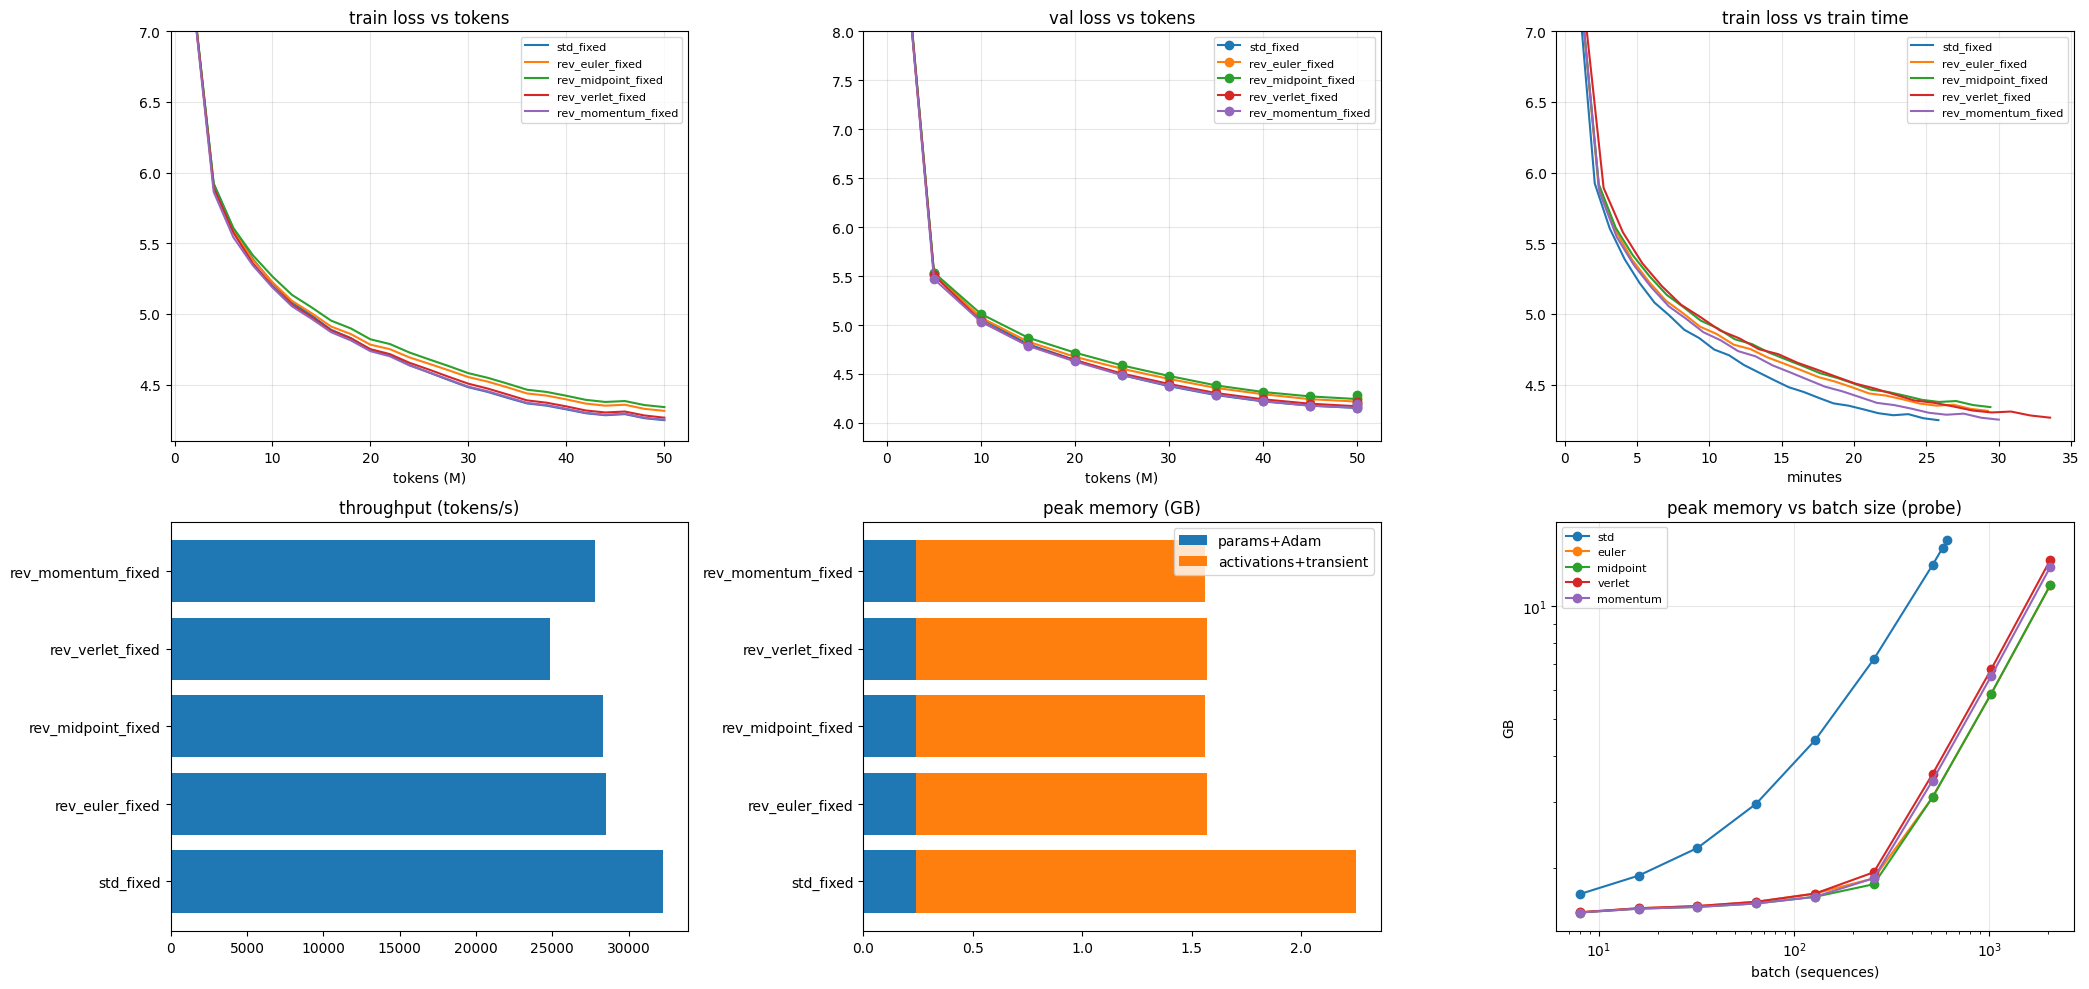


### SAMPLES
[std_fixed] 'The history of the city was that of the National Guard . The state of New York was a large city of New York , and its population was largely unshouted during the 1970s . A strong , small area of the town was formed in 1879 . \n The town also created a major village , the main streets'
[std_fixed] 'In 1998, the band released under pressure from the band at a time of nearly 500 years . The band had only been released in the month of 2009 , and was released on October 26 , 2009 . In Europe the band released the album The Last Rock Band , a limited album album , titled the " One Is That " , from'
[rev_euler_fixed] 'The history of the city was not a state of social life , even to become the state of the city . \n = = = = = Western history = = = = = \n By the mid @-@ 1970s the city of North Korea had been established in the town of Maita , and in the'
[rev_euler_fixed] 'In 1998, the band released their first album . The album began with a low success with heavy meta

In [17]:
banner("STAGE 8 - FINAL REPORT")
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
RUNS = RESULTS["runs"]; base = RUNS["std_fixed"]; bv = base["final_val_loss"]

def verdict(r):
    if r["arch"] == "std": return "baseline"
    if r["diverged"] or not math.isfinite(r["final_val_loss"]):
         return "FAILED (diverged)"
    if r.get("inv_trained") and r["inv_trained"]["amp"]["rel"] > 1e-2:
         return "UNRELIABLE (inversion drift)"
    d = r["final_val_loss"] - bv
    return "WORKS (=baseline)" if d <= 0.05 else "WORKS (small gap)" if d <= 0.25 else "WORKS (large gap)"

rows = []
for n, r in RUNS.items():
    rows.append(dict(run=n, arch=r["arch"], batch=r["batch"], steps=r["steps"], tokens_M=r["tokens"] / 1e6, peak_lr=r["lr"],
        train_loss=r["final_train_loss"], val_loss=r["final_val_loss"], val_ppl=math.exp(min(r["final_val_loss"], 50)),
        best_val=r["best_val_loss"], dval_vs_std=r["final_val_loss"] - bv,
        tok_s=r["tok_s_avg"], tok_s_steady=r["tok_s_steady"], speed_vs_std=r["tok_s_avg"] / base["tok_s_avg"],
        ms_step=r["step_time_ms"], peak_GB=r["peak_mem_gb"], reserved_GB=r["peak_reserved_gb"], act_GB=r["act_mem_gb"],
        mem_vs_std=r["peak_mem_gb"], train_min=r["train_time_s"] / 60,
        MFU_pct=100 * r["mfu"] if r["mfu"] else float("nan"), gnorm=r["final_gnorm"], nonfinite_grad_steps=r["nonfinite_grad_steps"],
        inv_err_trained=r["inv_trained"]["amp"]["rel"] if r.get("inv_trained") else float("nan"),
        grad_cos_trained=r["grad_fidelity_trained"]["cos"] if r.get("grad_fidelity_trained") else float("nan"),
        verdict=verdict(r)))
DF = pd.DataFrame(rows).set_index("run")
print("\n### MAIN RESULTS"); print(DF.to_string(float_format=lambda x: f"{x:.4g}"))
DF.to_csv(f"{OUT}/summary.csv")

print("\n### REVERSIBILITY DIAGNOSTICS (init)")
print(pd.DataFrame({v: {"inv_rel_fp32": d["inv_fp32"]["rel"], "inv_rel_amp": d["inv_amp"]["rel"], "inv_maxabs_amp": d["inv_amp"]["max_abs"],
                        "grad_cos_fp32": d["grad_fp32"]["cos"], "grad_relerr_fp32": d["grad_fp32"]["rel_err"],
                        "grad_cos_amp": d["grad_amp"]["cos"], "grad_relerr_amp": d["grad_amp"]["rel_err"]}
                    for v, d in RESULTS["diag"].items()}).T.to_string(float_format=lambda x: f"{x:.3e}"))

print("\n### MEMORY PROBE (max batch that fits one train step)")
print(pd.DataFrame({a: {"max_batch": p["max_batch"], "capped": p["capped"], "estimated": p["estimated"], "static_GB": p["static_gb"],
                        "act_MB_per_seq": p["act_mb_per_seq"], "x_vs_std": p["max_batch"] / RESULTS["probe"]["std"]["max_batch"],
                        "tok_s_at_largest": p["curve"][-1]["tok_s"] if p["curve"] else None}
                    for a, p in RESULTS["probe"].items()}).T.to_string())

print("\n### FINDINGS")
L = []
L.append(f"• Data {RESULTS['meta']['dataset']}; model {N_PARAMS/1e6:.2f}M params; {TOKENS_PER_RUN/1e6:.0f}M tokens/run on {HW_NAME} ({info['precision']}).")
L.append(f"• Baseline std @B={base['batch']}: train {base['final_train_loss']:.4f}, val {bv:.4f} (ppl {math.exp(bv):.1f}), "
         f"{base['tok_s_avg']:.0f} tok/s, peak {base['peak_mem_gb']:.2f} GB (activations {base['act_mem_gb']:.2f} GB), {base['train_time_s']/60:.1f} min.")
for v in CFG["variants"]:
    r = RUNS.get(f"rev_{v}_fixed")
    if not r: continue
    extra = (f"inversion err {r['inv_trained']['amp']['rel']:.1e} after training (init {RESULTS['diag'][v]['inv_amp']['rel']:.1e}), "
             f"grad cos vs autograd {r['grad_fidelity_trained']['cos']:.6f}") if r.get("inv_trained") else "n/a"
    L.append(f"• {v:9s} [{DF.loc[f'rev_{v}_fixed', 'verdict']}] val {r['final_val_loss']:.4f} (Δ {r['final_val_loss']-bv:+.4f}), speed {r['tok_s_avg']/base['tok_s_avg']-1:+.0f}%, peak mem {r['peak_mem_gb']/base['peak_mem_gb']-1:.2f}x "
             f"activation mem {r['act_mem_gb']/max(base['act_mem_gb'],1e-9):.2f}x; {extra}.")
pb = RESULTS["probe"]; best = RESULTS["meta"]["best_variant"]
L.append(f"• Max batch: std {pb['std']['max_batch']} vs {best} {pb[best]['max_batch']}{' (cap)' if pb[best]['capped'] else ''} "
         f"({pb[best]['max_batch']/pb['std']['max_batch']:.2f}x) | act MB/seq: std {pb['std']['act_mb_per_seq'] or float('nan'):.1f} vs {best} {pb[best]['act_mb_per_seq'] or float('nan'):.1f} MB/sequence.")
for n, r in RUNS.items():
    if n.endswith("_maxbatch"):
        ref = RUNS["std_fixed" if r["arch"] == "std" else f"rev_{r['arch']}_fixed"]
        L.append(f"• {n}: B={r['batch']} ({r['steps']} steps vs {ref['steps']}) | Δ lr {r['peak_lr']:.2e}: val {r['final_val_loss']:.4f} "
                 f"Δ {r['final_val_loss']-ref['final_val_loss']:+.4f} vs same arch @B={ref['batch']}, Δ {r['final_val_loss']-bv:+.4f} vs std), "
                 f"{r['tok_s_avg']:.0f} tok/s ({r['tok_s_avg']/ref['tok_s_avg']-1:+.2f}%), peak mem {r['peak_mem_gb']:.2f} GB, {r['train_time_s']/60:.1f} min.")
L.append("• Interpretation: reversible nets trade compute (inverse + re-forward per layer) for activation memory that no longer grows with depth.")
L.append("  At a fixed token budget a much larger batch means far fewer optimizer steps, so loss usually gets worse unless the GPU was under-utilised at the small batch.")
L.append("  Midpoint/leapfrog and momentum can drift numerically (momentum's inverse divides by γ); Euler/Verlet additive couplings are exact up to round-off.")
for line in L: print(line)
RESULTS["meta"]["findings"] = L; save_results()

fig, ax = plt.subplots(2, 3, figsize=(21, 10))
for n, r in RUNS.items():
    h = r["history"]
    ax[0, 0].plot([e["tokens"] / 1e6 for e in h], [e["loss" ] for e in h], label=n)
    ax[0, 1].plot([e[0] / 1e6 for e in r["evals"]], [e[1] for e in r["evals"]], marker="o", label=n)
    ax[0, 2].plot([e["train_time"] / 60 for e in h], [e["loss"] for e in h], label=n)
ax[0, 0].set_title("train loss vs tokens"); ax[0, 0].set_xlabel("tokens (M)"); ax[0, 0].set_ylim(None, 7); ax[0, 1].set_title("val loss vs tokens"); ax[0, 1].set_xlabel("tokens (M)"); ax[0, 1].set_ylim(None, 8)
ax[0, 2].set_title("train loss vs train time"); ax[0, 2].set_xlabel("minutes"); ax[0, 2].set_ylim(None, 7)
names = list(RUNS)
ax[1, 0].barh(names, [RUNS[n]["tok_s_avg"] for n in names]); ax[1, 0].set_title("throughput (tokens/s)")
ax[1, 1].barh(names, [RUNS[n]["static_mem_gb"] for n in names], label="params+Adam")
ax[1, 1].barh(names, [RUNS[n]["act_mem_gb"] for n in names], left=[RUNS[n]["static_mem_gb"] for n in names], label="activations+transient")
ax[1, 1].set_title("peak memory (GB)"); ax[1, 1].legend()
for a, p in RESULTS["probe"].items():
    ax[1, 2].plot([c["B"] for c in p["curve"]], [c["peak_gb"] for c in p["curve"]], marker="o", label=a)
ax[1, 2].set(title="peak memory vs batch size (probe)", xlabel="batch (sequences)", ylabel="GB", xscale="log", yscale="log")
for a_ in (ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 2]): a_.legend(fontsize=8); a_.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/report.png", dpi=120); plt.show()

print("\n### SAMPLES")
for n, r in RUNS.items():
    for s in r["samples"]: print(f"[{n}] {s!r}")
print(f"\nSaved: {RESULTS_PATH}, {OUT}/summary.csv, {OUT}/report.png")